# 04 — Internal-validation evaluation of Model A

## What this notebook does

- loads the saved study-level validation predictions from Notebook 03
- calculates AUROC and AUPRC
- selects operating thresholds on internal validation only
- reports sensitivity, specificity, precision, F1, false positives, and false negatives
- saves plots, a bootstrap confidence-interval table, and aggregate error summaries

The main operating policy is sensitivity ≥ 95%, because missing an abnormal study is an important risk for this project.


In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    roc_auc_score,
    roc_curve,
)

SEED = 42
BOOTSTRAP_ITERATIONS = 1000
PRIMARY_SENSITIVITY_TARGET = 0.95


## Connect Google Drive

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ModuleNotFoundError:
    pass

In [3]:
# Colab defaults may be overridden through local environment variables.
DATA_DIR = Path(os.environ.get('MURA_PROJECT_DATA_DIR', '/content/drive/MyDrive/DATA'))
MODEL_DIR = Path(os.environ.get('MURA_MODEL_A_DIR', str(DATA_DIR / 'BASELINE_MODEL_A')))
OUTPUT_DIR = MODEL_DIR / 'internal_validation_evaluation'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PREDICTIONS_PATH = MODEL_DIR / 'validation_predictions.csv'
RANKING_METRICS_PATH = MODEL_DIR / 'validation_ranking_metrics.json'
SELECTION_PATH = MODEL_DIR / 'model_selection.json'
RUN_METADATA_PATH = MODEL_DIR / 'run_metadata.json'
CANDIDATES_PATH = MODEL_DIR / 'logistic_regression_candidates.csv'

for required_path in (
    PREDICTIONS_PATH, RANKING_METRICS_PATH, SELECTION_PATH,
    RUN_METADATA_PATH, CANDIDATES_PATH,
):
    assert required_path.exists(), f'Notebook 03 output not found: {required_path}'

print({'model_artifacts_available': True, 'evaluation_directory_ready': OUTPUT_DIR.exists()})


{'model_artifacts_available': True, 'evaluation_directory_ready': True}


## Load and validate the saved baseline predictions

The checks below make sure this notebook is evaluating the intended development-validation output and not an official test file.

In [4]:
validation_predictions = pd.read_csv(PREDICTIONS_PATH)
saved_ranking_metrics = json.loads(RANKING_METRICS_PATH.read_text(encoding='utf-8'))
model_selection = json.loads(SELECTION_PATH.read_text(encoding='utf-8'))
run_metadata = json.loads(RUN_METADATA_PATH.read_text(encoding='utf-8'))
candidate_results = pd.read_csv(CANDIDATES_PATH)

required_columns = {
    'split', 'patient_id', 'study_id', 'label', 'num_views', 'abnormal_probability'
}
missing = required_columns - set(validation_predictions.columns)
assert not missing, f'Missing columns: {sorted(missing)}'
assert validation_predictions['split'].eq('validation').all()
assert validation_predictions['study_id'].is_unique
assert validation_predictions['label'].isin([0, 1]).all()
assert validation_predictions['num_views'].ge(1).all()
assert validation_predictions['abnormal_probability'].between(0, 1).all()

c_selection = model_selection['c_selection']
assert c_selection['selection_data'] == 'internal_train_patient_grouped_cv_only'
assert c_selection['group_field'] == 'patient_id'
assert c_selection['validation_labels_used_for_c_selection'] is False
assert model_selection['threshold_selection_data'] == 'internal_validation_only'
assert model_selection['test_used_for_selection'] is False
assert run_metadata['study_pooling'] == 'mean_embedding'
assert run_metadata['official_mura_valid_read'] is False

print('Guardrail check passed: C was selected by patient-grouped CV inside internal train; official MURA valid/test was not read.')
display(pd.DataFrame([{
    'validation_studies': len(validation_predictions),
    'validation_patients': validation_predictions['patient_id'].nunique(),
    'normal_studies': int((validation_predictions['label'] == 0).sum()),
    'abnormal_studies': int((validation_predictions['label'] == 1).sum()),
    'selected_logistic_C': c_selection['selected_c'],
    'group_cv_folds': c_selection['group_cv_folds'],
}]))
display(candidate_results)


Guardrail check passed: C was selected by patient-grouped CV inside internal train; official MURA valid/test was not read.


,validation_studies,validation_patients,normal_studies,abnormal_studies,selected_logistic_C,group_cv_folds
0,691,653,422,269,0.1,5


,C,train_grouped_cv_auroc,train_grouped_cv_auprc,group_cv_folds
0,0.1,0.860167,0.812326,5
1,1.0,0.834832,0.776060,5
2,10.0,0.819345,0.755193,5


## Ranking metrics

AUROC and AUPRC describe how well the model ranks studies. They do not depend on one chosen decision threshold.

In [5]:
y_true = validation_predictions['label'].to_numpy(dtype=int)
y_score = validation_predictions['abnormal_probability'].to_numpy(dtype=float)

ranking_metrics = {
    'split': 'internal_validation',
    'auroc': float(roc_auc_score(y_true, y_score)),
    'auprc': float(average_precision_score(y_true, y_score)),
}

assert np.isclose(ranking_metrics['auroc'], saved_ranking_metrics['auroc'])
assert np.isclose(ranking_metrics['auprc'], saved_ranking_metrics['auprc'])

display(pd.DataFrame([ranking_metrics]))

,split,auroc,auprc
0,internal_validation,0.880442,0.851514


## Threshold policies

Three policies are reported on the internal validation set:

1. **0.50 reference** — a simple fixed reference.
2. **Youden J** — a development diagnostic that balances sensitivity and specificity.
3. **Sensitivity ≥ 95%** — the pre-specified primary high-sensitivity policy. We choose the highest threshold that still reaches the target sensitivity, which preserves as much specificity as possible on this validation set.

The primary threshold is frozen after this validation-only selection. Threshold selection and reporting use the same development validation split here, so these are not final untouched-test results.


In [6]:
def classification_metrics(y_true, probabilities, threshold):
    predicted_abnormal = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true, predicted_abnormal, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan

    return {
        'threshold': float(threshold),
        'sensitivity': float(sensitivity),
        'specificity': float(specificity),
        'precision': float(precision_score(y_true, predicted_abnormal, zero_division=0)),
        'f1': float(f1_score(y_true, predicted_abnormal, zero_division=0)),
        'false_negative_rate': float(1 - sensitivity),
        'true_negative': int(tn),
        'false_positive': int(fp),
        'false_negative': int(fn),
        'true_positive': int(tp),
        'flagged_abnormal': int(predicted_abnormal.sum()),
        'flagged_percent': float(100 * predicted_abnormal.mean()),
    }


def threshold_table(y_true, probabilities):
    rows = []
    candidate_thresholds = np.unique(np.append(probabilities, 0.50))[::-1]
    for threshold in candidate_thresholds:
        row = classification_metrics(y_true, probabilities, threshold)
        row['youden_j'] = row['sensitivity'] + row['specificity'] - 1
        rows.append(row)

    return pd.DataFrame(rows)


def select_high_sensitivity_policy(table, target):
    eligible = table.loc[table['sensitivity'] >= target].copy()
    if eligible.empty:
        raise RuntimeError(f'No threshold reached sensitivity >= {target:.2f}.')

    return eligible.sort_values(
        ['threshold', 'specificity'], ascending=[False, False]
    ).iloc[0].to_dict()


In [7]:
all_thresholds = threshold_table(y_true, y_score)

reference_policy = classification_metrics(y_true, y_score, threshold=0.50)
youden_policy = all_thresholds.sort_values(
    ['youden_j', 'threshold'], ascending=[False, False]
).iloc[0].to_dict()
primary_policy = select_high_sensitivity_policy(
    all_thresholds, PRIMARY_SENSITIVITY_TARGET
)

policies = [
    ('Reference threshold 0.50', reference_policy, np.nan),
    ('Youden J (development diagnostic)', youden_policy, np.nan),
    (f'Primary: sensitivity >= {PRIMARY_SENSITIVITY_TARGET:.0%}', primary_policy, PRIMARY_SENSITIVITY_TARGET),
]

operating_point_rows = []
for policy_name, values, target in policies:
    row = {'policy': policy_name, 'target_sensitivity': target}
    row.update(values)
    operating_point_rows.append(row)

operating_points = pd.DataFrame(operating_point_rows)
all_thresholds['selected_policy'] = ''
for policy_name, values, _ in policies:
    selected = np.isclose(all_thresholds['threshold'], values['threshold'])
    all_thresholds.loc[selected, 'selected_policy'] = policy_name
display(operating_points)

,policy,target_sensitivity,threshold,sensitivity,specificity,precision,f1,false_negative_rate,true_negative,false_positive,false_negative,true_positive,flagged_abnormal,flagged_percent,youden_j
0,Reference threshold 0.50,NaN,0.500000,0.736059,0.888626,0.808163,0.770428,0.263941,375.0,47.0,71.0,198.0,245.0,35.455861,NaN
1,Youden J (development diagnostic),NaN,0.511352,0.736059,0.890995,0.811475,0.771930,0.263941,376.0,46.0,71.0,198.0,244.0,35.311143,0.627055
2,Primary: sensitivity >= 95%,0.95,0.063773,0.951673,0.393365,0.500000,0.655570,0.048327,166.0,256.0,13.0,256.0,512.0,74.095514,0.345038


## ROC and precision-recall curves

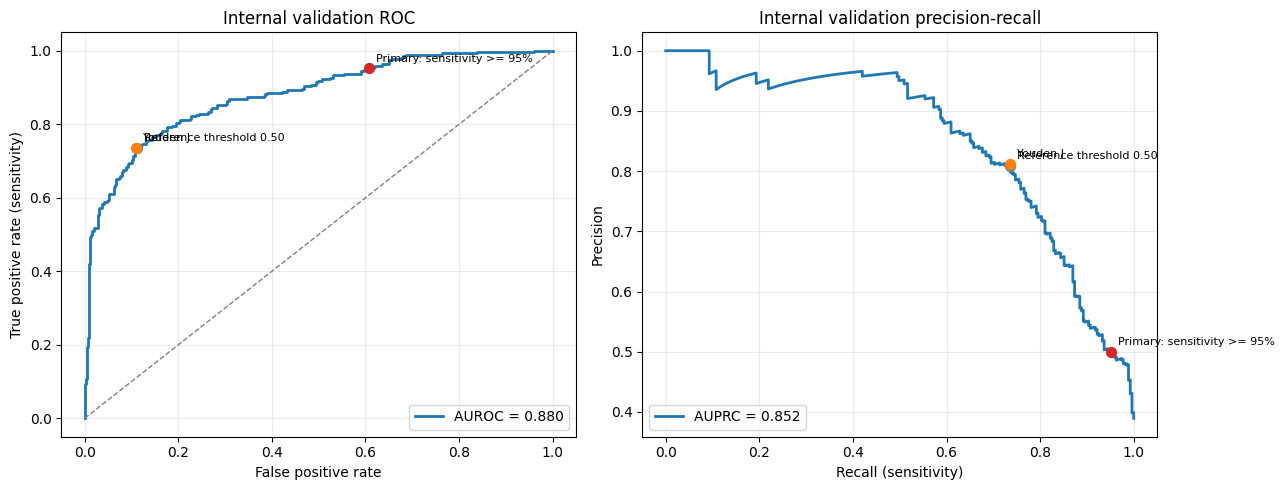

ROC/PR figure saved.


In [8]:
fpr, tpr, _ = roc_curve(y_true, y_score)
precision, recall, _ = precision_recall_curve(y_true, y_score)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, linewidth=2, label=f"AUROC = {ranking_metrics['auroc']:.3f}")
axes[0].plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate (sensitivity)')
axes[0].set_title('Internal validation ROC')
axes[0].grid(alpha=0.25)

axes[1].plot(recall, precision, linewidth=2, label=f"AUPRC = {ranking_metrics['auprc']:.3f}")
axes[1].set_xlabel('Recall (sensitivity)')
axes[1].set_ylabel('Precision')
axes[1].set_title('Internal validation precision-recall')
axes[1].grid(alpha=0.25)

colors = ['tab:gray', 'tab:orange', 'tab:red']
for axis, x_column, y_column in [
    (axes[0], 'specificity', 'sensitivity'),
    (axes[1], 'sensitivity', 'precision'),
]:
    for (_, row), color in zip(operating_points.iterrows(), colors):
        x_value = 1 - row[x_column] if x_column == 'specificity' else row[x_column]
        axis.scatter(x_value, row[y_column], color=color, s=50, zorder=3)
        axis.annotate(
            row['policy'].replace(' (development diagnostic)', ''),
            (x_value, row[y_column]),
            xytext=(5, 5),
            textcoords='offset points',
            fontsize=8,
        )

axes[0].legend(loc='lower right')
axes[1].legend(loc='lower left')
plt.tight_layout()

roc_pr_path = OUTPUT_DIR / 'internal_validation_roc_pr.png'
plt.savefig(roc_pr_path, dpi=180, bbox_inches='tight')
plt.show()
plt.close()

print('ROC/PR figure saved.')

## Sensitivity, specificity, and review workload tradeoff

This view shows why the chosen threshold matters: raising sensitivity generally means more studies are flagged for review and lower specificity.

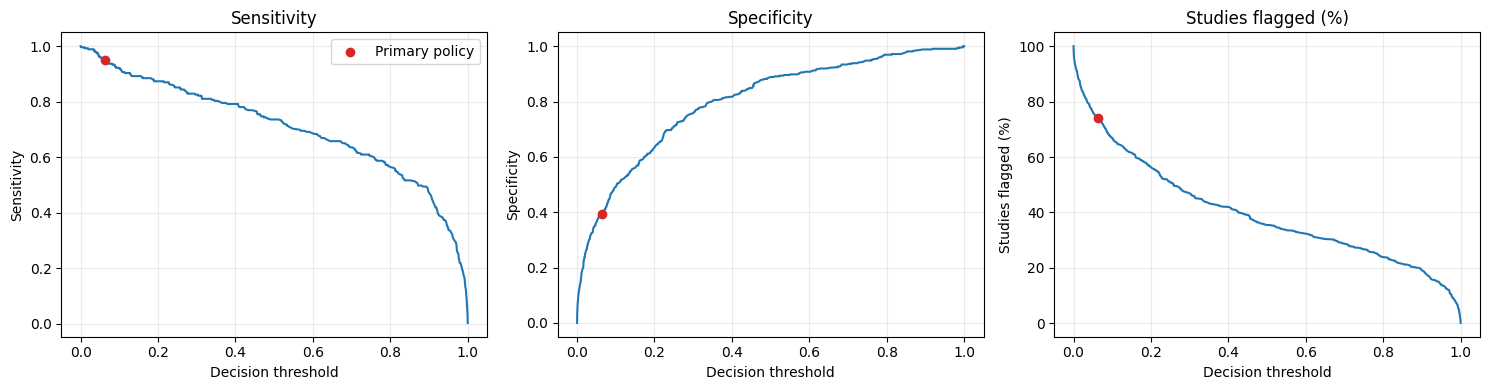

Threshold trade-off figure saved.


In [9]:
tradeoff = all_thresholds.sort_values('threshold')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

charts = [
    ('sensitivity', 'Sensitivity'),
    ('specificity', 'Specificity'),
    ('flagged_percent', 'Studies flagged (%)'),
]

for axis, (column, title) in zip(axes, charts):
    axis.plot(tradeoff['threshold'], tradeoff[column], color='tab:blue')
    axis.scatter(
        primary_policy['threshold'],
        primary_policy[column],
        color='tab:red',
        label='Primary policy',
        zorder=3,
    )
    axis.set_xlabel('Decision threshold')
    axis.set_ylabel(title)
    axis.set_title(title)
    axis.grid(alpha=0.25)

axes[0].legend()
plt.tight_layout()

tradeoff_path = OUTPUT_DIR / 'sensitivity_specificity_workload_tradeoff.png'
plt.savefig(tradeoff_path, dpi=180, bbox_inches='tight')
plt.show()
plt.close()

print('Threshold trade-off figure saved.')

## Confusion matrices

The high-sensitivity policy is the main result for the project. The Youden-J matrix is included only to show the tradeoff.

<local kernel>:20: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


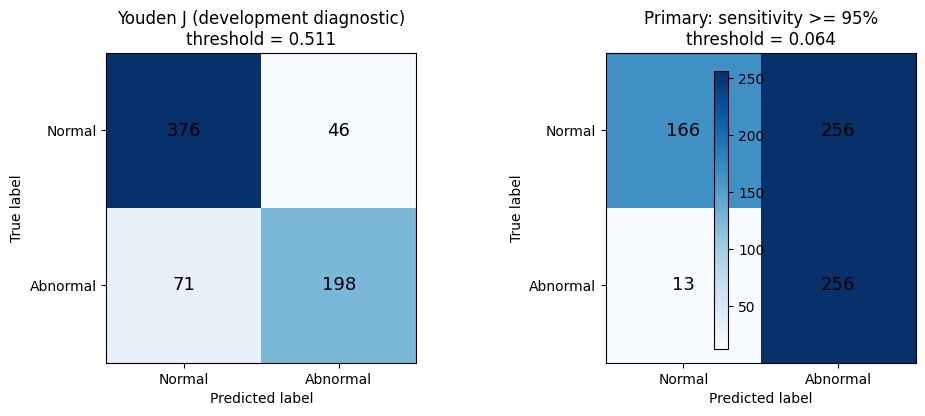

Confusion-matrix figure saved.


In [10]:
matrix_policies = operating_points.iloc[[1, 2]].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for axis, (_, row) in zip(axes, matrix_policies.iterrows()):
    predicted = (y_score >= row['threshold']).astype(int)
    matrix = confusion_matrix(y_true, predicted, labels=[0, 1])

    image = axis.imshow(matrix, cmap='Blues')
    for r in range(2):
        for c in range(2):
            axis.text(c, r, str(matrix[r, c]), ha='center', va='center', fontsize=13)

    axis.set_xticks([0, 1], labels=['Normal', 'Abnormal'])
    axis.set_yticks([0, 1], labels=['Normal', 'Abnormal'])
    axis.set_xlabel('Predicted label')
    axis.set_ylabel('True label')
    axis.set_title(f"{row['policy']}\nthreshold = {row['threshold']:.3f}")

fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.9)
plt.tight_layout()

confusion_path = OUTPUT_DIR / 'internal_validation_confusion_matrices.png'
plt.savefig(confusion_path, dpi=180, bbox_inches='tight')
plt.show()
plt.close()

print('Confusion-matrix figure saved.')

## Patient-cluster bootstrap confidence intervals

The bootstrap samples patients rather than individual image views, so all studies belonging to a sampled patient stay together. The selected threshold is treated as fixed here; the interval does not include uncertainty from model or threshold selection.

In [11]:
def bootstrap_confidence_intervals(frame, threshold, n_iterations, seed):
    patient_ids = frame['patient_id'].astype(str).to_numpy()
    unique_patients = np.unique(patient_ids)
    patient_indices = [np.flatnonzero(patient_ids == patient_id) for patient_id in unique_patients]

    y = frame['label'].to_numpy(dtype=int)
    scores = frame['abnormal_probability'].to_numpy(dtype=float)
    rng = np.random.default_rng(seed)
    samples = []

    for _ in range(n_iterations):
        chosen = rng.integers(0, len(unique_patients), size=len(unique_patients))
        indices = np.concatenate([patient_indices[index] for index in chosen])
        bootstrap_y = y[indices]

        if np.unique(bootstrap_y).size < 2:
            continue

        stats = classification_metrics(bootstrap_y, scores[indices], threshold)
        samples.append({
            'auroc': roc_auc_score(bootstrap_y, scores[indices]),
            'auprc': average_precision_score(bootstrap_y, scores[indices]),
            'sensitivity': stats['sensitivity'],
            'specificity': stats['specificity'],
            'precision': stats['precision'],
            'f1': stats['f1'],
        })

    return pd.DataFrame(samples)


primary_threshold = float(operating_points.iloc[2]['threshold'])
bootstrap_samples = bootstrap_confidence_intervals(
    validation_predictions,
    primary_threshold,
    BOOTSTRAP_ITERATIONS,
    SEED,
)
assert len(bootstrap_samples) >= int(BOOTSTRAP_ITERATIONS * 0.95)

point_estimates = {
    'auroc': ranking_metrics['auroc'],
    'auprc': ranking_metrics['auprc'],
    'sensitivity': float(operating_points.iloc[2]['sensitivity']),
    'specificity': float(operating_points.iloc[2]['specificity']),
    'precision': float(operating_points.iloc[2]['precision']),
    'f1': float(operating_points.iloc[2]['f1']),
}

bootstrap_intervals = pd.DataFrame([
    {
        'metric': metric,
        'point_estimate': point_estimates[metric],
        'lower_95_ci': float(bootstrap_samples[metric].quantile(0.025)),
        'upper_95_ci': float(bootstrap_samples[metric].quantile(0.975)),
    }
    for metric in point_estimates
])

display(bootstrap_intervals)
print(f'Valid bootstrap samples: {len(bootstrap_samples)} / {BOOTSTRAP_ITERATIONS}')

,metric,point_estimate,lower_95_ci,upper_95_ci
0,auroc,0.880442,0.853847,0.906501
1,auprc,0.851514,0.812140,0.888620
2,sensitivity,0.951673,0.926991,0.974366
3,specificity,0.393365,0.349169,0.441409
4,precision,0.500000,0.457357,0.543529
5,f1,0.655570,0.616225,0.693168


Valid bootstrap samples: 1000 / 1000


## Error tables for the primary high-sensitivity policy

These tables are for inspection only. MURA labels studies as NORMAL or ABNORMAL; they do not identify a specific acute fracture or lesion.

In [12]:
primary_predictions = validation_predictions.copy()
primary_predictions['threshold'] = primary_threshold
primary_predictions['predicted_label'] = (primary_predictions['abnormal_probability'] >= primary_threshold).astype(int)
primary_predictions['decision_margin'] = primary_predictions['abnormal_probability'] - primary_threshold

false_negatives = primary_predictions.loc[
    (primary_predictions['label'] == 1) & (primary_predictions['predicted_label'] == 0)
].sort_values('abnormal_probability')
false_positives = primary_predictions.loc[
    (primary_predictions['label'] == 0) & (primary_predictions['predicted_label'] == 1)
].sort_values('abnormal_probability', ascending=False)

# Keep study-level rows in saved local artifacts, but show only aggregate counts in the notebook.
error_summary = pd.DataFrame([{
    'false_negatives': len(false_negatives),
    'false_positives': len(false_positives),
    'threshold': primary_threshold,
}])
display(error_summary)


,false_negatives,false_positives,threshold
0,13,256,0.063773


## Results by number of views

This is a descriptive check. Small groups should not be interpreted as stable performance estimates.

In [13]:
def view_group(num_views):
    if num_views == 1:
        return '1 view'
    if num_views == 2:
        return '2 views'
    return '3+ views'


view_rows = []
for group_name, group in primary_predictions.assign(
    view_group=primary_predictions['num_views'].map(view_group)
).groupby('view_group', sort=False):
    group_y = group['label'].to_numpy(dtype=int)
    group_scores = group['abnormal_probability'].to_numpy(dtype=float)
    group_stats = classification_metrics(group_y, group_scores, primary_threshold)

    view_rows.append({
        'view_group': group_name,
        'studies': len(group),
        'abnormal_studies': int((group_y == 1).sum()),
        'normal_studies': int((group_y == 0).sum()),
        'auroc': roc_auc_score(group_y, group_scores) if np.unique(group_y).size == 2 else np.nan,
        'sensitivity': group_stats['sensitivity'],
        'specificity': group_stats['specificity'],
        'note': 'Interpret cautiously' if min((group_y == 1).sum(), (group_y == 0).sum()) < 10 else '',
    })

view_count_summary = pd.DataFrame(view_rows)
display(view_count_summary)

,view_group,studies,abnormal_studies,normal_studies,auroc,sensitivity,specificity,note
0,3+ views,499,222,277,0.864052,0.963964,0.285199,
1,2 views,138,41,97,0.884586,0.902439,0.474227,
2,1 view,54,6,48,0.916667,0.833333,0.854167,Interpret cautiously


## Save evaluation artifacts

In [14]:
operating_points_path = OUTPUT_DIR / 'operating_points.csv'
threshold_table_path = OUTPUT_DIR / 'threshold_table.csv'
ranking_metrics_path = OUTPUT_DIR / 'validation_ranking_metrics.json'
selected_policy_path = OUTPUT_DIR / 'selected_primary_operating_point.json'
bootstrap_path = OUTPUT_DIR / 'bootstrap_confidence_intervals.csv'
primary_predictions_path = OUTPUT_DIR / 'primary_policy_predictions.csv'
false_negatives_path = OUTPUT_DIR / 'primary_policy_false_negatives.csv'
false_positives_path = OUTPUT_DIR / 'primary_policy_false_positives.csv'
view_count_path = OUTPUT_DIR / 'primary_policy_by_view_count.csv'
config_path = OUTPUT_DIR / 'evaluation_protocol.json'
summary_path = OUTPUT_DIR / 'evaluation_summary.md'

operating_points.to_csv(operating_points_path, index=False)
all_thresholds.to_csv(threshold_table_path, index=False)
ranking_metrics_path.write_text(json.dumps(ranking_metrics, indent=2), encoding='utf-8')
bootstrap_intervals.to_csv(bootstrap_path, index=False)
primary_predictions.to_csv(primary_predictions_path, index=False)
false_negatives.to_csv(false_negatives_path, index=False)
false_positives.to_csv(false_positives_path, index=False)
view_count_summary.to_csv(view_count_path, index=False)

primary = operating_points.iloc[2]
selected_primary_policy = {
    'model': 'Frozen ResNet-18 embeddings + Logistic Regression',
    'study_aggregation': 'mean_embedding',
    'source_split': 'internal_validation',
    'selection_rule': 'highest threshold with sensitivity >= target',
    'target_sensitivity': float(PRIMARY_SENSITIVITY_TARGET),
    'test_used_for_selection': False,
    **{
        key: (int(primary[key]) if key in {'true_negative', 'false_positive', 'false_negative', 'true_positive', 'flagged_abnormal'} else float(primary[key]))
        for key in [
            'threshold', 'sensitivity', 'specificity', 'precision', 'f1', 'false_negative_rate',
            'true_negative', 'false_positive', 'false_negative', 'true_positive',
            'flagged_abnormal', 'flagged_percent',
        ]
    },
}
selected_policy_path.write_text(json.dumps(selected_primary_policy, indent=2), encoding='utf-8')

config_path.write_text(json.dumps({
    'split': 'internal_validation',
    'primary_sensitivity_target': PRIMARY_SENSITIVITY_TARGET,
    'primary_threshold': primary_threshold,
    'threshold_rule': 'highest validation threshold with sensitivity >= target',
    'bootstrap_unit': 'patient cluster',
    'bootstrap_iterations': BOOTSTRAP_ITERATIONS,
    'official_mura_valid_read': False,
}, indent=2), encoding='utf-8')

summary = f"""# Internal validation evaluation — baseline model

This report evaluates the frozen ImageNet ResNet-18 embedding + Logistic Regression baseline using the internal patient-level validation split only. It is a development result, not an untouched final-test result.

## Ranking metrics

- AUROC: {ranking_metrics['auroc']:.6f}
- AUPRC: {ranking_metrics['auprc']:.6f}

## Primary operating policy

The threshold was selected as the highest internal-validation threshold that achieved sensitivity ≥ {PRIMARY_SENSITIVITY_TARGET:.0%}.

- Threshold: {primary['threshold']:.6f}
- Sensitivity: {primary['sensitivity']:.4f}
- Specificity: {primary['specificity']:.4f}
- Precision: {primary['precision']:.4f}
- F1: {primary['f1']:.4f}
- False negatives: {int(primary['false_negative'])}
- False positives: {int(primary['false_positive'])}
- Studies flagged abnormal: {int(primary['flagged_abnormal'])} ({primary['flagged_percent']:.1f}%)

## Important limitation

Logistic Regression C was selected with patient-grouped cross-validation inside internal training only. The operating-policy threshold and performance reporting use the same internal validation population in this notebook. The bootstrap intervals treat the threshold as fixed and do not include threshold-selection uncertainty. The official MURA validation split was not read.
"""
summary_path.write_text(summary, encoding='utf-8')

for path in [
    operating_points_path, threshold_table_path, ranking_metrics_path, selected_policy_path,
    bootstrap_path, primary_predictions_path,
    false_negatives_path, false_positives_path, view_count_path,
    config_path, summary_path, roc_pr_path, tradeoff_path, confusion_path,
]:
    print('Saved:', path)

Saved: <local test workspace>/runtime\BASELINE_MODEL_A\internal_validation_evaluation\operating_points.csv
Saved: <local test workspace>/runtime\BASELINE_MODEL_A\internal_validation_evaluation\threshold_table.csv
Saved: <local test workspace>/runtime\BASELINE_MODEL_A\internal_validation_evaluation\validation_ranking_metrics.json
Saved: <local test workspace>/runtime\BASELINE_MODEL_A\internal_validation_evaluation\selected_primary_operating_point.json
Saved: <local test workspace>/runtime\BASELINE_MODEL_A\internal_validation_evaluation\bootstrap_confidence_intervals.csv
Saved: <local test workspace>/runtime\BASELINE_MODEL_A\internal_validation_evaluation\primary_policy_predictions.csv
Saved: <local test workspace>/runtime\BASELINE_MODEL_A\internal_validation_evaluation\primary_policy_false_negatives.csv
Saved: <local test workspace>/runtime\BASELINE_MODEL_A\internal_validation_evaluation\primary_policy_false_positives.csv
Saved: <local test workspace>/runtime\BASELINE_MODEL_A\internal_v

## Result status

The baseline pipeline is now evaluated on the internal validation split. Do not describe these numbers as final official-test results. The next modeling notebook can compare a fine-tuned model fairly against this saved baseline using the same split definitions and study-level metrics.